# Prime-time audience share: prediction model

Predict `share_15_54` of **channel 3** for 1 Nov 2023 – 13 Jan 2024. Metric: MAE (share points).
Builds on `eda.ipynb`. The final cell block defines a `Model` class with the exact
`fit(train)` / `predict(test)` interface required for `solution.py`.

**Approach**
- Clean: drop exact duplicates, never use `f_7`–`f_11` (empty in test), coerce types defensively.
- Features: calendar (hour, minute of evening, weekday, season, Czech holidays, Christmas),
  decoded `main_ident` (programme start, minutes since start, suffix), own + competitor `f_*`
  features, `share_15_54_3mo_mean` of ch3 and of the competitors in the same timeslot.
- Model: `HistGradientBoostingRegressor` with absolute-error loss (= the metric), trained on ch3 rows;
  NaN handled natively. Quantile models at 10% / 90% for an 80% prediction interval.
- Validation: time-based folds only, including a Nov–mid-Jan fold to mimic the test period (incl. Christmas).

In [1]:
import time
from pathlib import Path

import holidays
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "train.csv").exists())
DATA = ROOT / "data"
SEED = 42

C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = "#257de0", "#f47230", "#00b894", "#f2a600"
GRAY, TEXT2 = "#9c9c9c", "#666666"
mpl.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": TEXT2, "xtick.color": TEXT2, "ytick.color": TEXT2,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "axes.titleweight": "bold", "axes.titlesize": 12, "legend.frameon": False,
})

## 1. Feature engineering

Everything is computed from the frame itself, row-order independent, and tolerant of missing
columns, NaN and wrong dtypes (the organisers run hidden robustness tests). Competitor context is
taken from the other channels' rows **in the same timeslot**, which exist in test too.

In [2]:
TARGET, MO3 = "share_15_54", "share_15_54_3mo_mean"
CHANNELS, SCORED = [3, 4, 9, 54], 3
USE_F = [1, 2, 3, 4, 5, 6, 12]          # f_7..f_11 are empty in test -> never used
CTX_VARS = [MO3, "elapsed", "prog_start_min", "suffix"]
CZ_HOLIDAYS = pd.to_datetime(list(holidays.Czechia(years=range(2015, 2035)).keys()))

CALENDAR = ["hour", "minute_of_evening", "dow", "weekend", "doy_sin", "doy_cos", "holiday", "xmas", "summer"]
IDENT = ["elapsed", "prog_start_min", "suffix"]
LEVEL = [MO3, "n_channels"]
F_COLS = [f"ch{c}__f_{i}" for c in CHANNELS for i in USE_F]
CTX_COLS = [f"ctx_{v}_ch{c}" for c in CHANNELS if c != SCORED for v in CTX_VARS]
FEATURES = CALENDAR + IDENT + LEVEL + F_COLS + CTX_COLS


def decode_ident(df):
    """main_ident = <channel_id><YYMMDDHHMMSS programme start><4-digit suffix>."""
    ident = pd.to_numeric(df["main_ident"], errors="coerce").astype("Int64").astype(str)
    ch = pd.to_numeric(df["channel_id"], errors="coerce").astype("Int64").astype(str)
    rest = pd.Series([a[len(b):] if a.startswith(b) else "" for a, b in zip(ident, ch)], index=df.index)
    start = pd.to_datetime(rest.str[:12], format="%y%m%d%H%M%S", errors="coerce")
    return start, pd.to_numeric(rest.str[12:], errors="coerce")


def build_features(df):
    """Raw train/test frame -> frame with all FEATURES (+ original columns). Index preserved."""
    df = df.copy()
    for col in ["main_ident", "timeslot_datetime_from", "channel_id", MO3, *F_COLS]:
        if col not in df:
            df[col] = np.nan
    df["channel_id"] = pd.to_numeric(df["channel_id"], errors="coerce")
    df[MO3] = pd.to_numeric(df[MO3], errors="coerce")
    for col in F_COLS:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    t = pd.to_datetime(df["timeslot_datetime_from"], errors="coerce")
    df["t"] = t
    start, suffix = decode_ident(df)
    df["elapsed"] = (t - start).dt.total_seconds() / 60
    df["prog_start_min"] = (start.dt.hour - 16) * 60 + start.dt.minute + start.dt.second / 60
    df["suffix"] = suffix

    # calendar
    df["hour"] = t.dt.hour
    df["minute_of_evening"] = (t.dt.hour - 16) * 60 + t.dt.minute
    df["dow"] = t.dt.dayofweek
    df["weekend"] = (df["dow"] >= 5).astype(float).where(t.notna())
    doy = t.dt.dayofyear
    df["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    df["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    df["holiday"] = t.dt.normalize().isin(CZ_HOLIDAYS).astype(float).where(t.notna())
    md_ = t.dt.month * 100 + t.dt.day
    df["xmas"] = ((md_ >= 1220) | (md_ <= 106)).astype(float).where(t.notna())
    df["summer"] = t.dt.month.isin([7, 8]).astype(float).where(t.notna())

    # competitor context: other channels' rows in the same timeslot
    slot = df["timeslot_datetime_from"].astype(str)
    ctx = (df.assign(_slot=slot).dropna(subset=["channel_id"])
             .groupby(["_slot", "channel_id"])[CTX_VARS].first().unstack("channel_id"))
    ctx.columns = [f"ctx_{v}_ch{int(c)}" for v, c in ctx.columns]
    ctx = ctx.reindex(columns=CTX_COLS)
    df = df.join(ctx, on=slot)
    df["n_channels"] = df.groupby(slot)["channel_id"].transform("size").astype(float)
    return df


def clean_train(raw):
    df = raw.drop_duplicates()
    df = df[pd.to_numeric(df[TARGET], errors="coerce").between(0, 100)]
    return df.reset_index(drop=True)

In [3]:
train_raw = pd.read_csv(DATA / "train.csv", low_memory=False)
test_raw = pd.read_csv(DATA / "test.csv", low_memory=False)
train = build_features(clean_train(train_raw))
train[TARGET] = train[TARGET].astype(float)
c3 = train[train["channel_id"] == SCORED].reset_index(drop=True)
print(f"train rows after cleaning: {len(train)} (ch3: {len(c3)}), features: {len(FEATURES)}")
c3[FEATURES].describe().T[["count", "mean", "min", "max"]].round(2).head(25)

train rows after cleaning: 16157 (ch3: 4002), features: 54


,count,mean,min,max
hour,4002.0,19.67,16.00,23.00
minute_of_evening,4002.0,248.48,0.00,475.00
dow,4002.0,3.02,0.00,6.00
weekend,4002.0,0.29,0.00,1.00
doy_sin,4002.0,0.04,-1.00,1.00
doy_cos,4002.0,-0.07,-1.00,1.00
holiday,4002.0,0.03,0.00,1.00
xmas,4002.0,0.04,0.00,1.00
summer,4002.0,0.19,0.00,1.00
elapsed,4002.0,38.77,-4.97,200.43


## 2. Validation scheme

Time-based folds (train only on the past, validate on a later window):

| fold | train on | validate on | why |
|---|---|---|---|
| `Xmas22` | < 1 Nov 2022 | 1 Nov 2022 – 13 Jan 2023 | same season as test, incl. Christmas |
| `MayJun23` | < 1 May 2023 | May – Jun 2023 | ordinary period |
| `SepOct23` | < 1 Sep 2023 | Sep – Oct 2023 | closest to test, most training data |

Metrics follow the jury: overall MAE, MAE by evening segment, and worst-week MAE.
Segment boundaries are our assumption: early 16:00–18:59, prime 19:00–21:59, late 22:00–23:59.

In [4]:
FOLDS = {
    "Xmas22": ("2022-11-01", "2023-01-14"),
    "MayJun23": ("2023-05-01", "2023-07-01"),
    "SepOct23": ("2023-09-01", "2023-11-01"),
}


def split(df, start, end):
    return df[df["t"] < start], df[(df["t"] >= start) & (df["t"] < end)]


def segment(hour):
    return pd.cut(hour, [15, 18, 21, 24], labels=["early", "prime", "late"])


def report(val, pred):
    err = (val[TARGET].to_numpy() - np.asarray(pred))
    e = pd.Series(np.abs(err), index=val.index)
    seg = e.groupby(segment(val["hour"]), observed=True).mean()
    week = e.groupby(val["t"].dt.to_period("W")).mean()
    return {"MAE": e.mean(), **{f"MAE_{k}": v for k, v in seg.items()},
            "worst_week": week.max(), "bias": -err.mean()}

## 3. Baselines

In [5]:
def baseline_preds(fit, val):
    hd = fit.groupby(["hour", "dow"])[TARGET].mean()
    hd_pred = pd.Series(list(zip(val["hour"], val["dow"])), index=val.index).map(hd)
    return {
        "global mean": np.full(len(val), fit[TARGET].mean()),
        "3mo_mean": val[MO3].to_numpy(),
        "hour x weekday": hd_pred.fillna(fit[TARGET].mean()).to_numpy(),
    }

rows = []
for fold, (s, e) in FOLDS.items():
    fit, val = split(c3, s, e)
    for name, p in baseline_preds(fit, val).items():
        rows.append({"fold": fold, "model": name, **report(val, p)})
baselines = pd.DataFrame(rows)
baselines.pivot(index="model", columns="fold", values="MAE").assign(mean=lambda d: d.mean(axis=1)).round(3)

fold,MayJun23,SepOct23,Xmas22,mean
model,,,,
3mo_mean,5.098,5.433,4.667,5.066
global mean,6.535,6.708,5.755,6.332
hour x weekday,4.526,4.541,4.478,4.515


## 4. Model and feature-set comparison

Gradient boosting with absolute-error loss. Feature sets are added step by step to see what each
group contributes. (Hyper-parameters were tuned lightly offline: lr 0.03, 800 iterations, 15 leaves;
deeper/longer models and residual or ratio targets on `3mo_mean` were not better.)

In [6]:
PARAMS = dict(loss="absolute_error", learning_rate=0.03, max_iter=800, max_leaf_nodes=15,
              min_samples_leaf=30, l2_regularization=1.0, random_state=SEED)


def fit_hgb(df, feats, **kw):
    return HistGradientBoostingRegressor(**{**PARAMS, **kw}).fit(df[feats], df[TARGET])


FEATURE_SETS = {
    "calendar": CALENDAR,
    "+ ident": CALENDAR + IDENT,
    "+ 3mo level": CALENDAR + IDENT + LEVEL,
    "+ own/competitor f_*": CALENDAR + IDENT + LEVEL + F_COLS,
    "+ competitor context (final)": FEATURES,
}
rows = []
t0 = time.time()
for name, feats in FEATURE_SETS.items():
    for fold, (s, e) in FOLDS.items():
        fit, val = split(c3, s, e)
        m = fit_hgb(fit, feats)
        rows.append({"fold": fold, "model": name, **report(val, m.predict(val[feats]))})
print(f"{time.time() - t0:.0f}s")
results = pd.concat([baselines, pd.DataFrame(rows)])
order = list(baselines["model"].unique()) + list(FEATURE_SETS)
tab = results.pivot(index="model", columns="fold", values="MAE").reindex(order)
tab.assign(mean=tab.mean(axis=1)).round(3)

53s


fold,MayJun23,SepOct23,Xmas22,mean
model,,,,
global mean,6.535,6.708,5.755,6.332
3mo_mean,5.098,5.433,4.667,5.066
hour x weekday,4.526,4.541,4.478,4.515
calendar,3.914,4.166,4.227,4.102
+ ident,3.650,4.411,3.910,3.990
+ 3mo level,3.707,4.252,4.046,4.002
+ own/competitor f_*,3.641,4.172,4.042,3.952
+ competitor context (final),3.636,4.112,3.976,3.908


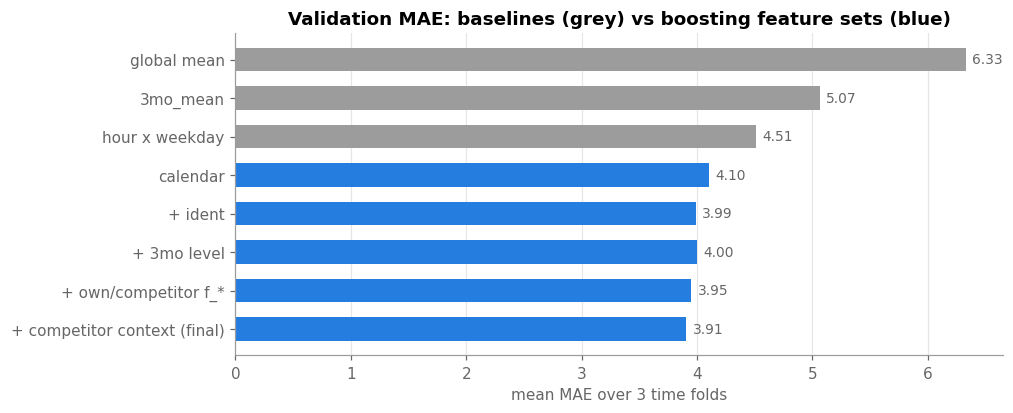

In [7]:
tab_mean = tab.mean(axis=1)
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(tab_mean))[::-1]
colors = [GRAY] * len(baselines["model"].unique()) + [C_BLUE] * len(FEATURE_SETS)
ax.barh(y, tab_mean.values, color=colors, height=0.6)
for yi, v in zip(y, tab_mean.values):
    ax.annotate(f"{v:.2f}", (v, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=TEXT2)
ax.set(yticks=y, yticklabels=tab_mean.index, xlabel="mean MAE over 3 time folds",
       title="Validation MAE: baselines (grey) vs boosting feature sets (blue)")
ax.grid(axis="y", visible=False)
plt.show()

- The biggest step is from a lookup table to boosting on calendar features alone (4.52 → 4.10).
- Gains after that are small and **not uniform across folds**: programme timing (`+ ident`) helps
  May–Jun and Christmas but hurts Sep–Oct; adding `3mo_mean` is neutral on average.
- Own/competitor `f_*` and competitor context add ~0.1 together, and the full set is the best on
  average, so we keep it. The differences between the last three rows are within fold-to-fold noise.

## 5. Final configuration: jury-style metrics

In [8]:
final = results[results["model"] == "+ competitor context (final)"].set_index("fold")
ref = results[results["model"] == "hour x weekday"].set_index("fold")
cols = ["MAE", "MAE_early", "MAE_prime", "MAE_late", "worst_week", "bias"]
pd.concat({"model": final[cols], "hour x weekday": ref[cols]}, axis=1).round(2)

model                                               hour x weekday                                              
           MAE MAE_early MAE_prime MAE_late worst_week  bias            MAE MAE_early MAE_prime MAE_late worst_week  bias
fold                                                                                                                     
Xmas22    3.98      3.87      4.18     3.85       5.44  1.75           4.48      4.12      4.72     4.63       7.54  0.98
MayJun23  3.64      3.51      3.47     3.99       4.64  0.39           4.53      3.83      5.03     4.77       5.18  0.16
SepOct23  4.11      3.34      4.07     5.29       4.72 -0.48           4.54      3.53      4.95     5.26       5.15 -0.45

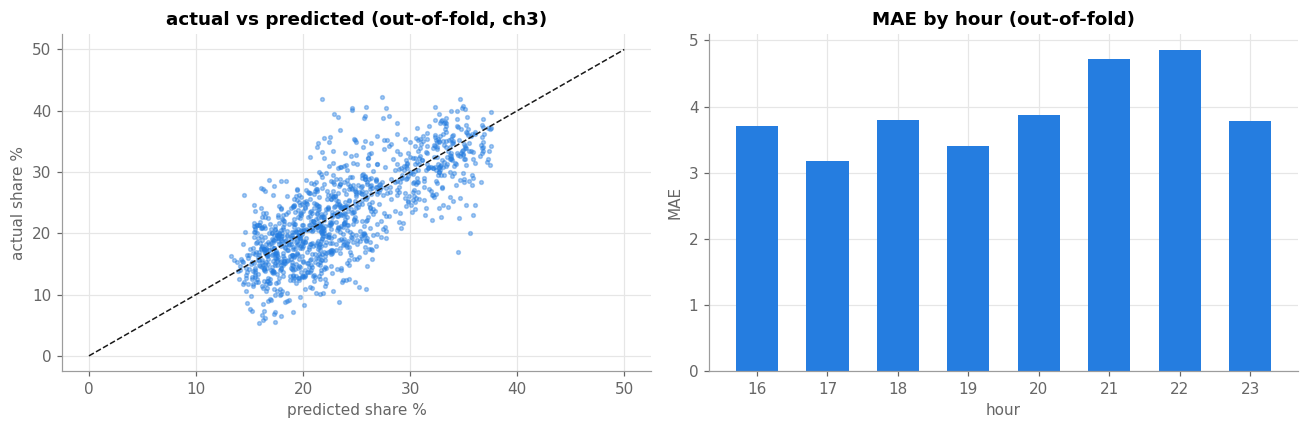

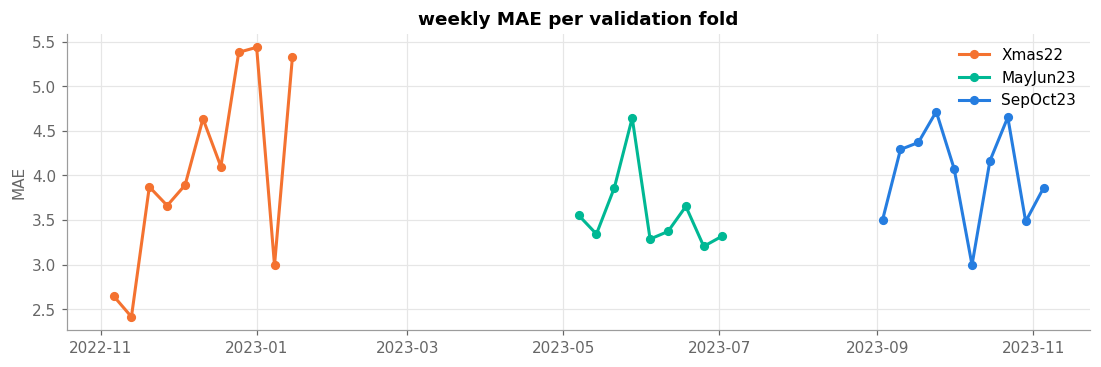

In [9]:
# out-of-fold predictions of the final model for plots
oof = []
for fold, (s, e) in FOLDS.items():
    fit, val = split(c3, s, e)
    m = fit_hgb(fit, FEATURES)
    oof.append(val.assign(pred=m.predict(val[FEATURES]), fold=fold))
oof = pd.concat(oof)
oof["abs_err"] = (oof[TARGET] - oof["pred"]).abs()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(oof["pred"], oof[TARGET], s=6, alpha=0.4, color=C_BLUE)
axes[0].plot([0, 50], [0, 50], color="#191919", linewidth=1, linestyle="--")
axes[0].set(title="actual vs predicted (out-of-fold, ch3)", xlabel="predicted share %", ylabel="actual share %")
h = oof.groupby("hour")["abs_err"].mean()
axes[1].bar(h.index, h.values, color=C_BLUE, width=0.6)
axes[1].set(title="MAE by hour (out-of-fold)", xlabel="hour", ylabel="MAE")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 3.5))
for fold, color in zip(FOLDS, [C_ORANGE, C_AQUA, C_BLUE]):
    w = oof[oof["fold"] == fold].set_index("t")["abs_err"].resample("W").mean()
    ax.plot(w.index, w.values, marker="o", markersize=5, color=color, label=fold)
ax.set(title="weekly MAE per validation fold", ylabel="MAE"); ax.legend()
plt.show()

In [10]:
print("Worst 10 out-of-fold slots:")
oof.nlargest(10, "abs_err")[["timeslot_datetime_from", "fold", "hour", "dow", "elapsed", TARGET, "pred", "abs_err"]].round(2)

Worst 10 out-of-fold slots:


,timeslot_datetime_from,fold,hour,dow,elapsed,share_15_54,pred,abs_err
2934,2023-05-06T23:25:00.000000,MayJun23,23,5,93.50,41.99,21.79,20.21
2970,2023-05-14T19:55:00.000000,MayJun23,19,6,25.00,16.97,34.51,17.54
3666,2023-09-11T21:25:00.000000,SepOct23,21,0,61.77,39.42,22.84,16.57
1992,2022-12-02T22:05:00.000000,Xmas22,22,4,99.68,40.38,24.53,15.85
3919,2023-10-16T21:25:00.000000,SepOct23,21,0,62.25,38.95,23.23,15.71
2980,2023-05-15T19:50:00.000000,MayJun23,19,0,20.00,20.07,35.63,15.57
3771,2023-09-25T21:55:00.000000,SepOct23,21,0,13.82,40.09,24.61,15.47
3014,2023-05-21T19:30:00.000000,MayJun23,19,6,0.00,10.95,25.87,14.92
3718,2023-09-18T22:45:00.000000,SepOct23,22,0,61.48,42.25,27.38,14.87
3920,2023-10-16T21:40:00.000000,SepOct23,21,0,77.25,40.55,25.85,14.70


- The model beats hour × weekday in every fold and segment except late evening in Sep–Oct 2023
  (5.29 vs 5.26), and its worst week is much better in the Christmas fold (5.44 vs 7.54).
- **Late-evening Sep–Oct 2023** is the weak spot: the worst misses are Monday 21–23h slots with ~40% share
  predicted at ~23–27%. Something new and very successful started on Mondays that season; nothing in
  the history tells the model about it.
- In the Christmas fold the model **over-predicts by 1.75 points on average** (`bias` = mean(pred − actual)):
  the 2022 holiday season was weaker than the months before. Worth watching for the test period too.

## 6. What drives the prediction: permutation importance (SepOct23 fold)

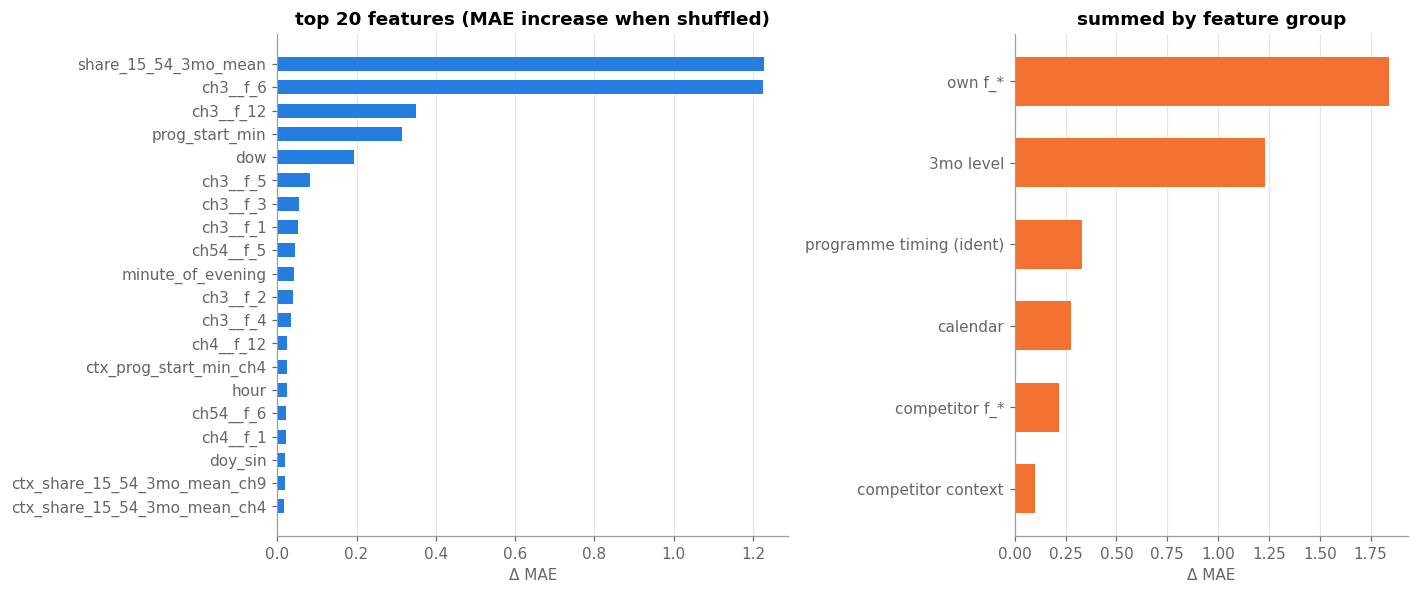

In [11]:
fit, val = split(c3, *FOLDS["SepOct23"])
m = fit_hgb(fit, FEATURES)
pi = permutation_importance(m, val[FEATURES], val[TARGET], scoring="neg_mean_absolute_error",
                            n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)

def group(f):
    if f in CALENDAR: return "calendar"
    if f in IDENT: return "programme timing (ident)"
    if f in LEVEL: return "3mo level"
    if f.startswith("ch3__"): return "own f_*"
    if f.startswith("ctx_"): return "competitor context"
    return "competitor f_*"

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
top = imp.head(20)[::-1]
axes[0].barh(top.index, top.values, color=C_BLUE, height=0.6)
axes[0].set(title="top 20 features (MAE increase when shuffled)", xlabel="Δ MAE")
axes[0].grid(axis="y", visible=False)
g = imp.groupby(imp.index.map(group)).sum().sort_values()
axes[1].barh(g.index, g.values, color=C_ORANGE, height=0.6)
axes[1].set(title="summed by feature group", xlabel="Δ MAE"); axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

- Inside the final model, `3mo_mean` and own `ch3__f_6` carry most of the weight, followed by `f_12`,
  programme start time and weekday.
- This does not contradict §4 (adding `3mo_mean` was neutral there): the 3-month level is time-of-day
  specific and overlaps with calendar features, so the model can get similar information either way.
  Permutation importance shows what *this* model relies on, not what is irreplaceable.
- Calendar features look small here for the same reason: their information is shared with `3mo_mean`.

## 7. Prediction intervals (optional extra)

Goal: "80% chance the share is between X and Y", with evidence that it holds. Three methods,
each evaluated on every fold and separately over Christmas (20 Dec – 6 Jan):

- **raw quantiles**: boosting with quantile loss at 10% / 90%;
- **CQR**: those quantiles widened by a conformal correction measured on the last 3 months of the
  training window (models refit without that window to measure it);
- **abs-residual conformal**: prediction ± the 80th percentile of |error| on the last 3 months.

In [12]:
def calib_split(fit, months=3):
    cut = fit["t"].max() - pd.DateOffset(months=months)
    return fit[fit["t"] < cut], fit[fit["t"] >= cut]


rows = []
for fold, (s, e) in FOLDS.items():
    fit, val = split(c3, s, e)
    inner, cal = calib_split(fit)
    y = val[TARGET].to_numpy()
    xm = val["xmas"].to_numpy() == 1

    lo = fit_hgb(fit, FEATURES, loss="quantile", quantile=0.1).predict(val[FEATURES])
    hi = fit_hgb(fit, FEATURES, loss="quantile", quantile=0.9).predict(val[FEATURES])

    lo_i = fit_hgb(inner, FEATURES, loss="quantile", quantile=0.1).predict(cal[FEATURES])
    hi_i = fit_hgb(inner, FEATURES, loss="quantile", quantile=0.9).predict(cal[FEATURES])
    q_cqr = np.quantile(np.maximum(lo_i - cal[TARGET], cal[TARGET] - hi_i), 0.8)

    q_abs = np.quantile(np.abs(cal[TARGET] - fit_hgb(inner, FEATURES).predict(cal[FEATURES])), 0.8)
    p = fit_hgb(fit, FEATURES).predict(val[FEATURES])

    for name, (a, b) in {"raw quantiles": (lo, hi), "CQR": (lo - q_cqr, hi + q_cqr),
                         "abs-residual conformal": (p - q_abs, p + q_abs)}.items():
        inside = (y >= a) & (y <= b)
        rows.append({"method": name, "fold": fold, "coverage": inside.mean(), "width": (b - a).mean(),
                     "coverage Christmas": inside[xm].mean() if xm.any() else np.nan})
iv = pd.DataFrame(rows)
iv.pivot(index="method", columns="fold", values="coverage").assign(
    Christmas=iv.groupby("method")["coverage Christmas"].first(),
    mean_width=iv.groupby("method")["width"].mean()).round(3)

fold,MayJun23,SepOct23,Xmas22,Christmas,mean_width
method,,,,,
CQR,0.850,0.740,0.852,0.750,13.387
abs-residual conformal,0.791,0.792,0.780,0.679,12.199
raw quantiles,0.640,0.522,0.610,0.500,8.609


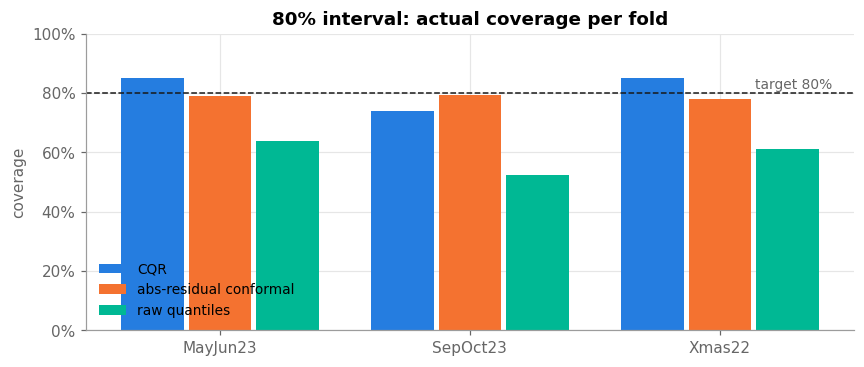

In [13]:
pv = iv.pivot(index="method", columns="fold", values="coverage")
fig, ax = plt.subplots(figsize=(9, 3.5))
x = np.arange(len(pv.columns))
for k, (method, color) in enumerate(zip(pv.index, [C_BLUE, C_ORANGE, C_AQUA])):
    ax.bar(x + (k - 1) * 0.27, pv.loc[method], 0.25, color=color, label=method)
ax.axhline(0.8, color="#191919", linewidth=1, linestyle="--")
ax.annotate("target 80%", (x[-1] + 0.45, 0.8), xytext=(0, 3), textcoords="offset points", fontsize=9, color=TEXT2, ha="right")
ax.set(xticks=x, xticklabels=pv.columns, ylim=(0, 1), ylabel="coverage", title="80% interval: actual coverage per fold")
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax.legend(loc="lower left", fontsize=9)
plt.show()

- Raw quantile models are **over-confident** (52–64% instead of 80%) and are not usable as-is.
- **Abs-residual conformal** is the most reliable: 78–79% on every fold with a ±6-point band. It goes into `Model`.
- **Over Christmas it under-covers** (~68%), because holiday slots are harder to predict than the
  calibration window. For a broadcaster, widen the band over Christmas or calibrate on
  the previous year's holiday season.

## 8. Submission `Model`

Same features and parameters, wrapped in the required interface. Defensive behaviour:
- duplicates and invalid targets dropped in `fit`;
- `predict` is row-order independent (context is joined by timeslot, not by position);
- any NaN prediction falls back to hour × weekday mean → `3mo_mean` → global mean; output clipped to [0, 100];
- rows of channels 4/9/54 get 0.

In [14]:
class Model:
    def __init__(self) -> None:
        self.seed = 42
        self.params = dict(PARAMS, random_state=self.seed)

    def fit(self, train: pd.DataFrame) -> None:
        df = build_features(clean_train(train))
        df[TARGET] = df[TARGET].astype(float)
        df = df[df["channel_id"] == SCORED]
        self.model = HistGradientBoostingRegressor(**self.params).fit(df[FEATURES], df[TARGET])
        self.hour_dow = df.groupby(["hour", "dow"])[TARGET].mean()
        self.global_mean = float(df[TARGET].mean())
        # half-width of the 80% interval: abs-residual conformal on the last 3 months
        inner, cal = calib_split(df)
        m_inner = HistGradientBoostingRegressor(**self.params).fit(inner[FEATURES], inner[TARGET])
        self.half_width = float(np.quantile(np.abs(cal[TARGET] - m_inner.predict(cal[FEATURES])), 0.8))

    def predict(self, test: pd.DataFrame) -> np.ndarray:
        df = build_features(test.reset_index(drop=True))
        pred = pd.Series(self.model.predict(df[FEATURES]), index=df.index)
        fallback = pd.Series(list(zip(df["hour"], df["dow"])), index=df.index).map(self.hour_dow)
        pred = pred.fillna(fallback).fillna(df[MO3]).fillna(self.global_mean).clip(0, 100)
        pred[df["channel_id"] != SCORED] = 0.0
        return pred.to_numpy(dtype=float)

    def predict_interval(self, test: pd.DataFrame) -> pd.DataFrame:
        """Extra (not used by the scorer): 80% interval per row."""
        p = self.predict(test)
        return pd.DataFrame({"pred": p, "lo80": np.clip(p - self.half_width, 0, 100),
                             "hi80": np.clip(p + self.half_width, 0, 100)})

In [15]:
t0 = time.time()
model = Model()
model.fit(train_raw)
test_in = test_raw.drop(columns="row_id")
pred = model.predict(test_in)
print(f"fit + predict: {time.time() - t0:.1f}s (limit 4 min)")

# checks mirroring check_submission.py + own robustness tests
assert len(pred) == len(test_in) and np.isfinite(pred).all()
perm = np.random.default_rng(0).permutation(len(test_in))
assert np.allclose(model.predict(test_in.iloc[perm]), pred[perm]), "prediction depends on row order"

broken = test_in.copy()
broken.loc[broken.sample(frac=0.2, random_state=1).index, [MO3, "ch3__f_3", "ch4__f_4"]] = np.nan
broken = broken.drop(columns=["ch54__f_12"]).astype({"channel_id": str})
p_broken = model.predict(broken)
assert np.isfinite(p_broken).all()
is3 = test_in["channel_id"].to_numpy() == SCORED
print("robustness: 20% NaN in key columns + dropped column + str channel_id -> finite;",
      f"mean |Δ| on ch3 = {np.abs(p_broken - pred)[is3].mean():.2f}")
print("all checks passed")
print(f"80% interval half-width: ±{model.half_width:.2f} share points")

fit + predict: 7.0s (limit 4 min)
robustness: 20% NaN in key columns + dropped column + str channel_id -> finite; mean |Δ| on ch3 = 0.44
all checks passed
80% interval half-width: ±6.55 share points


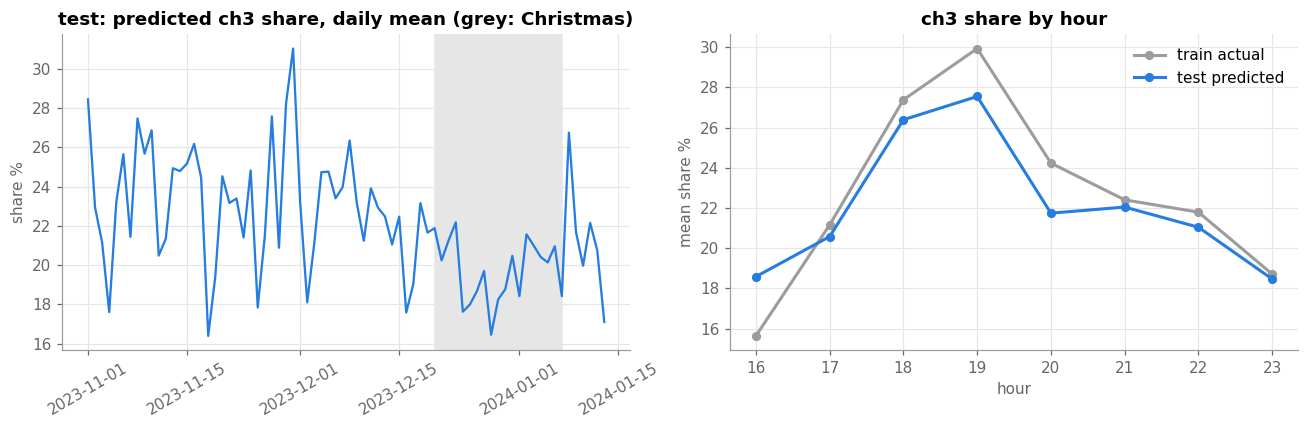

test ch3 predictions: {'count': 435.0, 'mean': 21.8, 'std': 4.84, 'min': 13.42, '25%': 18.43, '50%': 21.02, '75%': 23.85, 'max': 34.95}


In [16]:
test_feat = build_features(test_in)
t3 = test_feat.assign(pred=pred)[is3]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
d = t3.set_index("t")["pred"].resample("D").mean()
axes[0].plot(d.index, d.values, color=C_BLUE, linewidth=1.5)
axes[0].axvspan(pd.Timestamp("2023-12-20"), pd.Timestamp("2024-01-07"), color="#e6e6e6", zorder=0)
axes[0].set(title="test: predicted ch3 share, daily mean (grey: Christmas)", ylabel="share %")
axes[0].tick_params(axis="x", rotation=30)
hp = pd.DataFrame({"train actual": c3.groupby("hour")[TARGET].mean(), "test predicted": t3.groupby("hour")["pred"].mean()})
axes[1].plot(hp.index, hp["train actual"], marker="o", markersize=5, color=GRAY, label="train actual")
axes[1].plot(hp.index, hp["test predicted"], marker="o", markersize=5, color=C_BLUE, label="test predicted")
axes[1].set(title="ch3 share by hour", xlabel="hour", ylabel="mean share %"); axes[1].legend()
plt.tight_layout(); plt.show()
print("test ch3 predictions:", pd.Series(t3["pred"]).describe().round(2).to_dict())

## 9. Summary and next steps

- Gradient boosting on calendar, programme timing (decoded `main_ident`), the 3-month level and
  own/competitor programme features: **mean MAE 3.91** on three time folds vs 4.52 for the best
  lookup baseline (hour × weekday); better in every fold, including the Christmas season.
- Weak spots: late evening in Sep–Oct 2023 (new successful Monday programme), and a +1.75 over-prediction
  over the 2022 holiday season.
- 80% intervals (abs-residual conformal) hold ~78–79% coverage on normal periods but only ~68% over
  Christmas.
- The `Model` class above is ready to copy into `solution.py` together with `build_features`,
  `clean_train`, `calib_split` and the constants; `requirements.txt` needs `scikit-learn` and `holidays`
  (pinned). Fit + predict takes a few seconds.
- Ideas to try next: features for Christmas specials (24–26 Dec, 31 Dec), school breaks, big sports
  events; a holiday-specific bias correction; averaging with a model trained on all channels.